# 02 – EDA
Mọi thống kê chi tiêu là gross purchase value của khách có ID, chưa trừ hoàn trả. Hồ sơ toàn kỳ chỉ dùng mô tả. Unknown khác nhóm quốc gia đã biết nhưng chưa có trong bảng tham chiếu.

In [1]:
import os
import sys
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "src").is_dir() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from src.customer_features import build_customer_profiles
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

os.makedirs(ROOT / "reports/figures", exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 120

df = pd.read_parquet(ROOT / "data/processed/retail_processed.parquet")
print(f"Tổng số dòng giao dịch: {len(df):,} | Số khách hàng duy nhất: {df['customer_id'].nunique():,}")

Tổng số dòng giao dịch: 794,437 | Số khách hàng duy nhất: 5,876


In [2]:
# W6 – Phân tích mô tả trên đơn mua hợp lệ và khách có ít nhất một đơn
from src.data_quality import describe_numeric
df_valid = df.loc[~df['is_cancelled']].copy()
df_cancel = df.loc[df['is_cancelled']].copy()
customer_df = build_customer_profiles(df)
print(f"Hồ sơ: {len(customer_df):,} khách hàng; {len(df_valid):,} dòng mua hợp lệ.")
display(describe_numeric(df_valid, ['quantity','price','total_amount']).round(3))
corr_cols = ['recency_days','tenure_days','frequency','total_items','unique_products','monetary',
             'avg_order_value','weekend_ratio','peak_month_ratio','cancel_rate']
display(describe_numeric(customer_df, corr_cols + ['observation_days']).round(3))
# So sánh cấp khách hàng, không nhầm tổng chi tiêu với doanh thu ròng.
def grouped(col):
    table = customer_df.groupby(col).agg(
        n=('customer_id','size'), gross_gbp=('monetary','sum'),
        median_spend_gbp=('monetary','median'), mean_spend_gbp=('monetary','mean'),
        median_aov_gbp=('avg_order_value','median'), median_frequency=('frequency','median'),
        median_observation_days=('observation_days','median'), repeat_share=('is_repeat_buyer','mean'))
    return table.sort_values('n',ascending=False)
display(grouped('region').round(3))
display(grouped('is_uk').round(3))
print('Observation days và khách mua buôn có thể gây nhiễu so sánh chi tiêu/tần suất; không diễn giải nhân quả. W9 có phân tích cohort 365 ngày.')

Hồ sơ: 5,853 khách hàng; 776,844 dòng mua hợp lệ.


,count,mean,median,std,var,min,max,skew,kurt,p01,p25,p75,p95,p99,IQR,range,CV
quantity,776844.0,13.515,6.00,146.072,21336.962,1.000,80995.0,400.665,208292.770,1.00,2.00,12.00,36.0,144.00,10.00,80994.000,10.808
price,776844.0,2.950,1.95,4.379,19.175,0.001,649.5,31.377,2443.002,0.29,1.25,3.75,8.5,12.75,2.50,649.499,1.485
total_amount,776844.0,21.988,12.48,225.895,51028.463,0.001,168469.6,592.875,416723.160,0.62,4.95,19.80,67.5,201.60,14.85,168469.599,10.274


,count,mean,median,std,var,min,max,skew,kurt,p01,p25,p75,p95,p99,IQR,range,CV
recency_days,5853.0,199.783,95.000,208.542,4.348973e+04,0.00,738.00,0.894,-0.459,1.000,25.00,379.000,623.000,726.000,354.000,738.00,1.044
tenure_days,5853.0,274.391,223.000,258.493,6.681852e+04,1.00,739.00,0.386,-1.346,1.000,1.00,512.000,713.000,733.000,511.000,738.00,0.942
frequency,5853.0,6.253,3.000,12.760,1.628270e+02,1.00,375.00,12.078,241.948,1.000,1.00,7.000,20.000,46.000,6.000,374.00,2.041
total_items,5853.0,1793.782,484.000,8890.626,7.904323e+07,1.00,367072.00,21.825,664.976,12.000,189.00,1352.000,5354.400,16725.280,1163.000,367071.00,4.956
unique_products,5853.0,82.186,45.000,116.502,1.357260e+04,1.00,2547.00,6.222,85.133,1.000,19.00,103.000,281.000,502.960,84.000,2546.00,1.418
monetary,5853.0,2918.354,856.030,14335.234,2.054989e+08,2.95,580987.04,25.296,845.716,45.787,340.85,2240.900,9269.796,28626.153,1900.050,580984.09,4.912
avg_order_value,5853.0,384.546,277.935,1254.582,1.573976e+06,2.95,84236.25,53.391,3447.399,37.890,176.12,410.659,872.207,1906.729,234.539,84233.30,3.262
weekend_ratio,5853.0,0.141,0.000,0.265,7.000000e-02,0.00,1.00,2.175,3.886,0.000,0.00,0.167,1.000,1.000,0.167,1.00,1.879
peak_month_ratio,5853.0,0.484,0.500,0.363,1.320000e-01,0.00,1.00,0.133,-1.253,0.000,0.20,0.800,1.000,1.000,0.600,1.00,0.750
cancel_rate,5853.0,0.112,0.000,0.161,2.600000e-02,0.00,0.80,1.306,0.697,0.000,0.00,0.200,0.500,0.550,0.200,0.80,1.444


,n,gross_gbp,median_spend_gbp,mean_spend_gbp,median_aov_gbp,median_frequency,median_observation_days,repeat_share
region,,,,,,,,
Domestic_UK,5334,1.429165e+07,829.440,2679.349,269.726,3.0,540.0,0.725
Western_Europe,286,2.010202e+06,1200.995,7028.680,366.342,3.0,464.5,0.759
Southern_Europe,92,2.208540e+05,911.050,2400.587,423.200,2.0,446.5,0.696
Northern_Europe,54,2.208560e+05,1225.450,4089.926,457.615,2.0,434.5,0.611
Asia_Pacific,28,2.288239e+05,1026.625,8172.282,383.859,2.0,454.0,0.643
Other_International,14,4.486674e+04,2464.025,3204.767,819.753,3.5,504.0,0.857
North_America,13,1.225211e+04,534.240,942.470,360.000,1.0,271.0,0.385
Middle_East,12,2.250660e+04,1224.970,1875.550,1076.434,1.5,402.0,0.500
Eastern_Europe,8,1.589371e+04,825.100,1986.714,334.625,2.0,242.0,0.750


,n,gross_gbp,median_spend_gbp,mean_spend_gbp,median_aov_gbp,median_frequency,median_observation_days,repeat_share
is_uk,,,,,,,,
UK,5334,1.429165e+07,829.440,2679.349,269.726,3.0,540.0,0.725
International,500,2.732477e+06,1119.950,5464.953,398.520,3.0,445.0,0.698
Mixed,12,4.723705e+04,3797.955,3936.421,424.802,7.5,506.5,1.000
Unknown,7,9.766600e+03,552.000,1395.229,300.930,2.0,376.0,0.714


Observation days và khách mua buôn có thể gây nhiễu so sánh chi tiêu/tần suất; không diễn giải nhân quả. W9 có phân tích cohort 365 ngày.


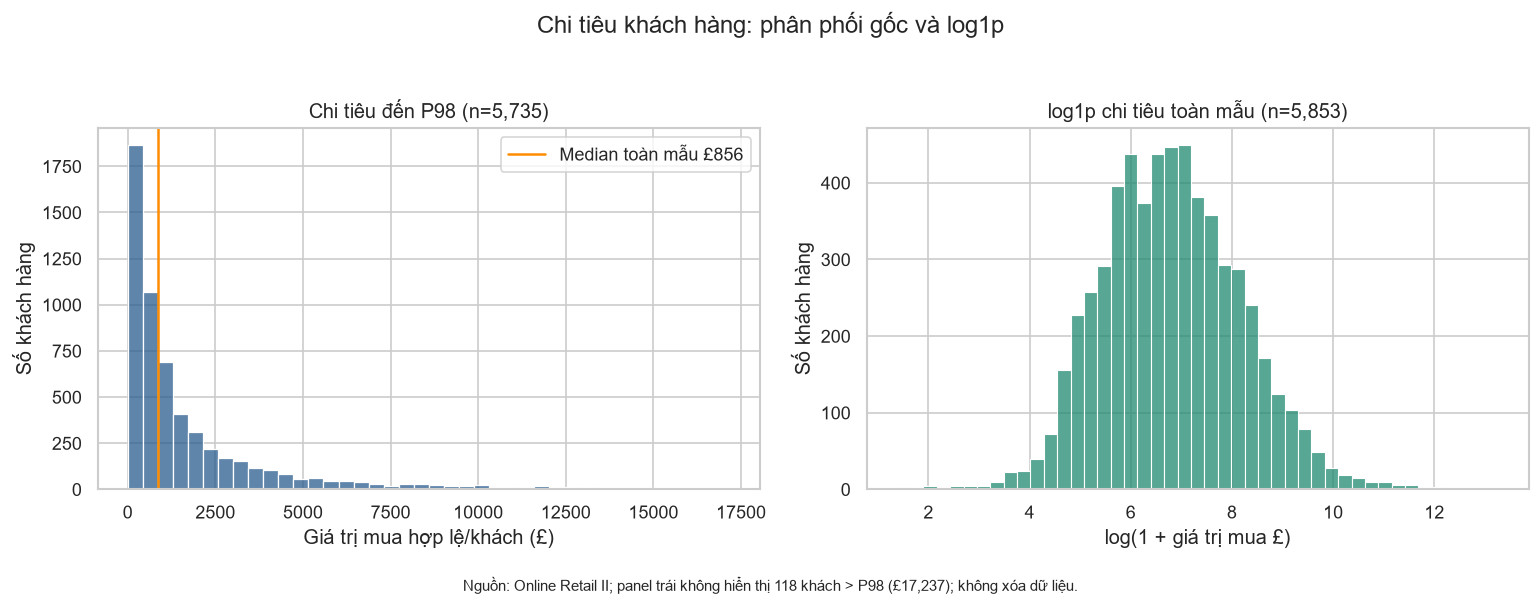

In [3]:
# W7 – Chia bins trong phạm vi biểu diễn, báo rõ phần đuôi bị loại khỏi panel trái
monetary = customer_df['monetary']
p98 = monetary.quantile(.98)
shown = monetary[monetary <= p98]
fig, axes = plt.subplots(1,2,figsize=(13,5))
sns.histplot(shown, bins=40, ax=axes[0], color='#2b5c8f')
axes[0].set(title=f'Chi tiêu đến P98 (n={len(shown):,})', xlabel='Giá trị mua hợp lệ/khách (£)', ylabel='Số khách hàng')
axes[0].axvline(monetary.median(), color='darkorange', label=f'Median toàn mẫu £{monetary.median():,.0f}')
axes[0].legend()
sns.histplot(np.log1p(monetary), bins=45, ax=axes[1], color='#1f8a70')
axes[1].set(title=f'log1p chi tiêu toàn mẫu (n={len(monetary):,})', xlabel='log(1 + giá trị mua £)', ylabel='Số khách hàng')
fig.suptitle('Chi tiêu khách hàng: phân phối gốc và log1p')
fig.text(.5,.015,f'Nguồn: Online Retail II; panel trái không hiển thị {len(monetary)-len(shown):,} khách > P98 (£{p98:,.0f}); không xóa dữ liệu.',ha='center',fontsize=9)
fig.tight_layout(rect=[0,.05,1,.95])
fig.savefig(ROOT / 'reports/figures/01_monetary_distribution.png',dpi=300,bbox_inches='tight')
plt.show()

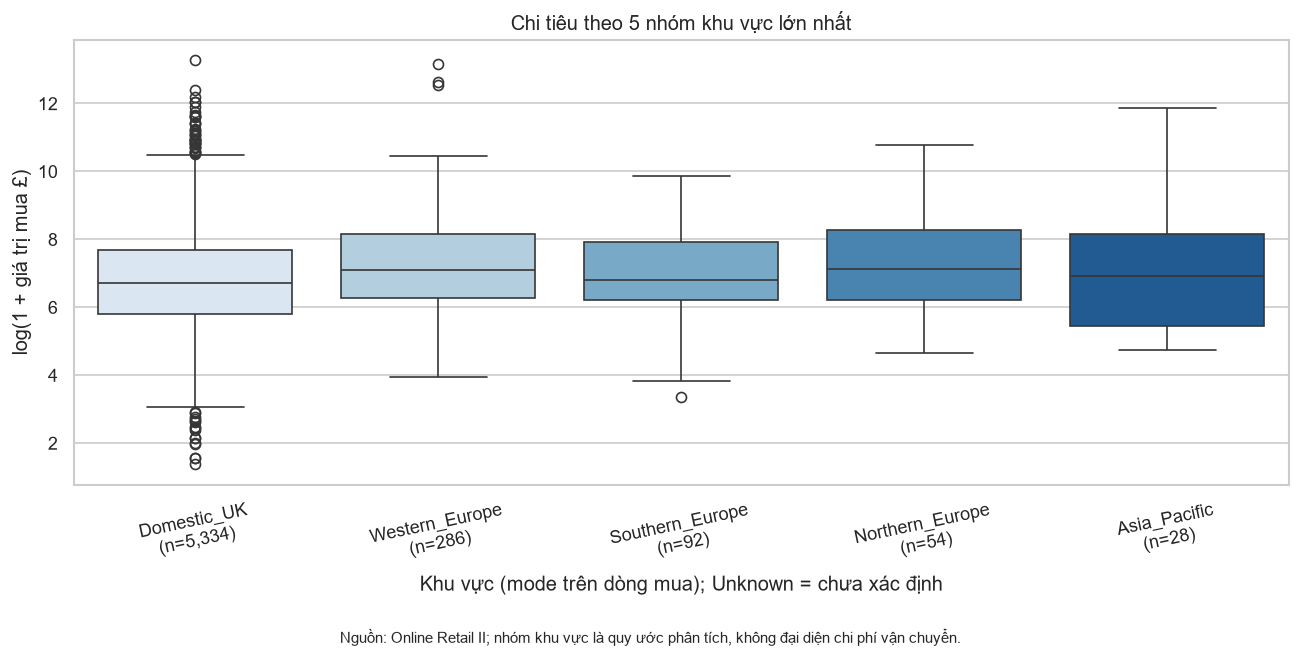

In [4]:
top_regions = customer_df['region'].value_counts().head(5).index.tolist()
df_reg = customer_df[customer_df['region'].isin(top_regions)].copy()
df_reg['log_monetary'] = np.log1p(df_reg['monetary'])
fig, ax = plt.subplots(figsize=(11,5.5))
sns.boxplot(data=df_reg,x='region',y='log_monetary',order=top_regions,hue='region',hue_order=top_regions,legend=False,showfliers=True,palette='Blues',ax=ax)
counts = df_reg['region'].value_counts()
ax.set_xticks(range(len(top_regions)),[f'{r}\n(n={counts[r]:,})' for r in top_regions],rotation=12)
ax.set(title='Chi tiêu theo 5 nhóm khu vực lớn nhất',xlabel='Khu vực (mode trên dòng mua); Unknown = chưa xác định',ylabel='log(1 + giá trị mua £)')
fig.text(.5,.01,'Nguồn: Online Retail II; nhóm khu vực là quy ước phân tích, không đại diện chi phí vận chuyển.',ha='center',fontsize=9)
fig.tight_layout(rect=[0,.05,1,1])
fig.savefig(ROOT / 'reports/figures/02_spending_by_region.png',dpi=300,bbox_inches='tight')
plt.show()

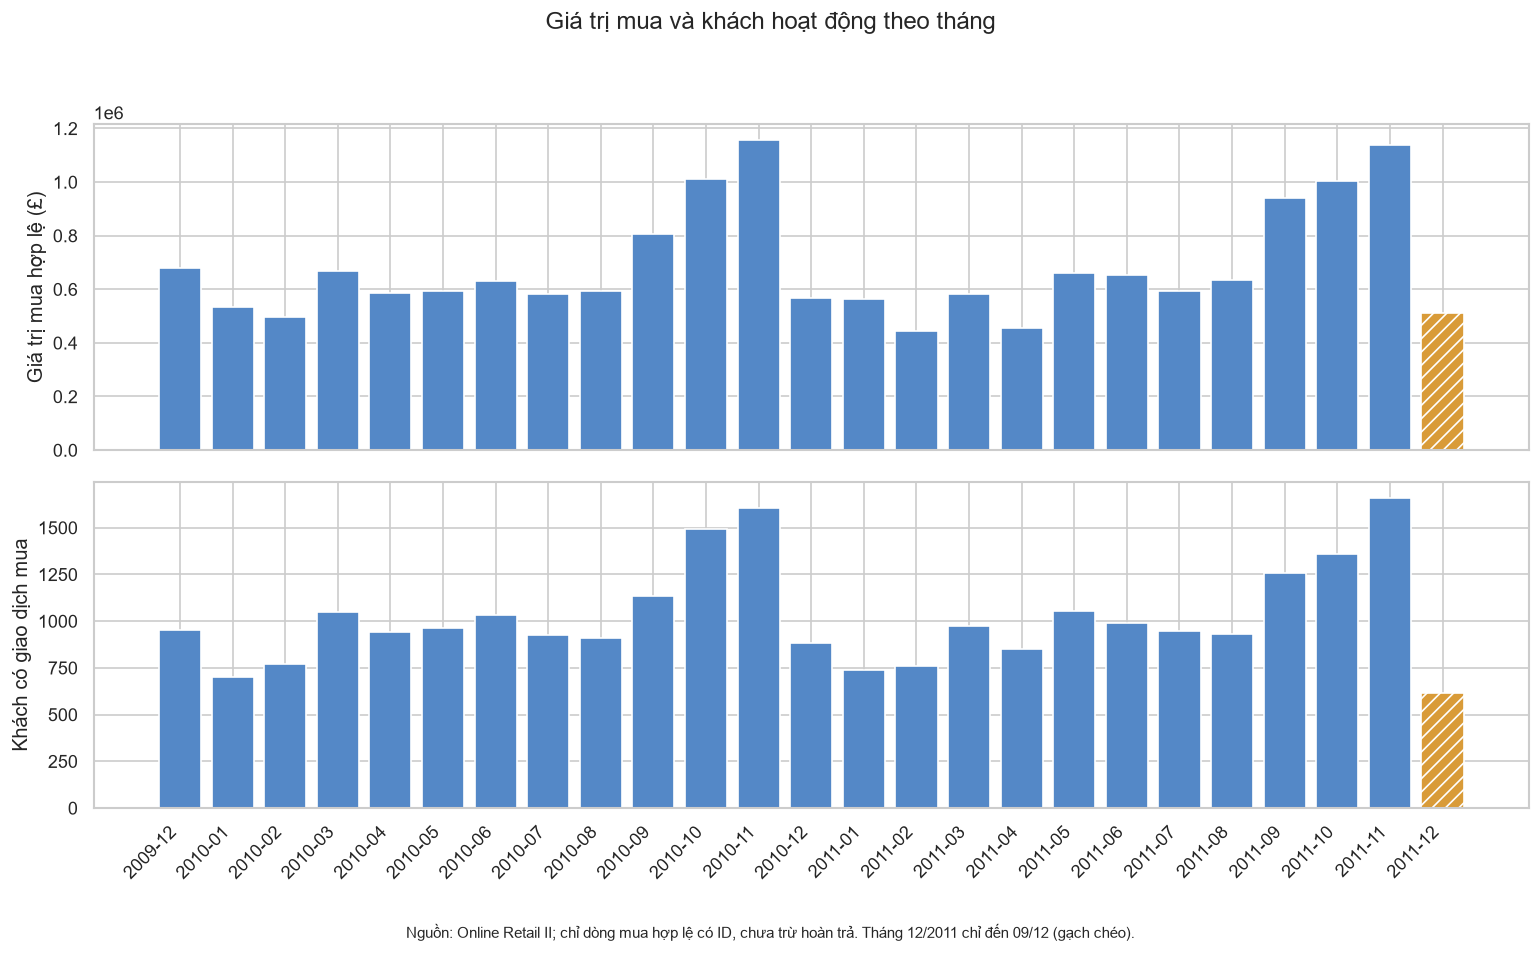

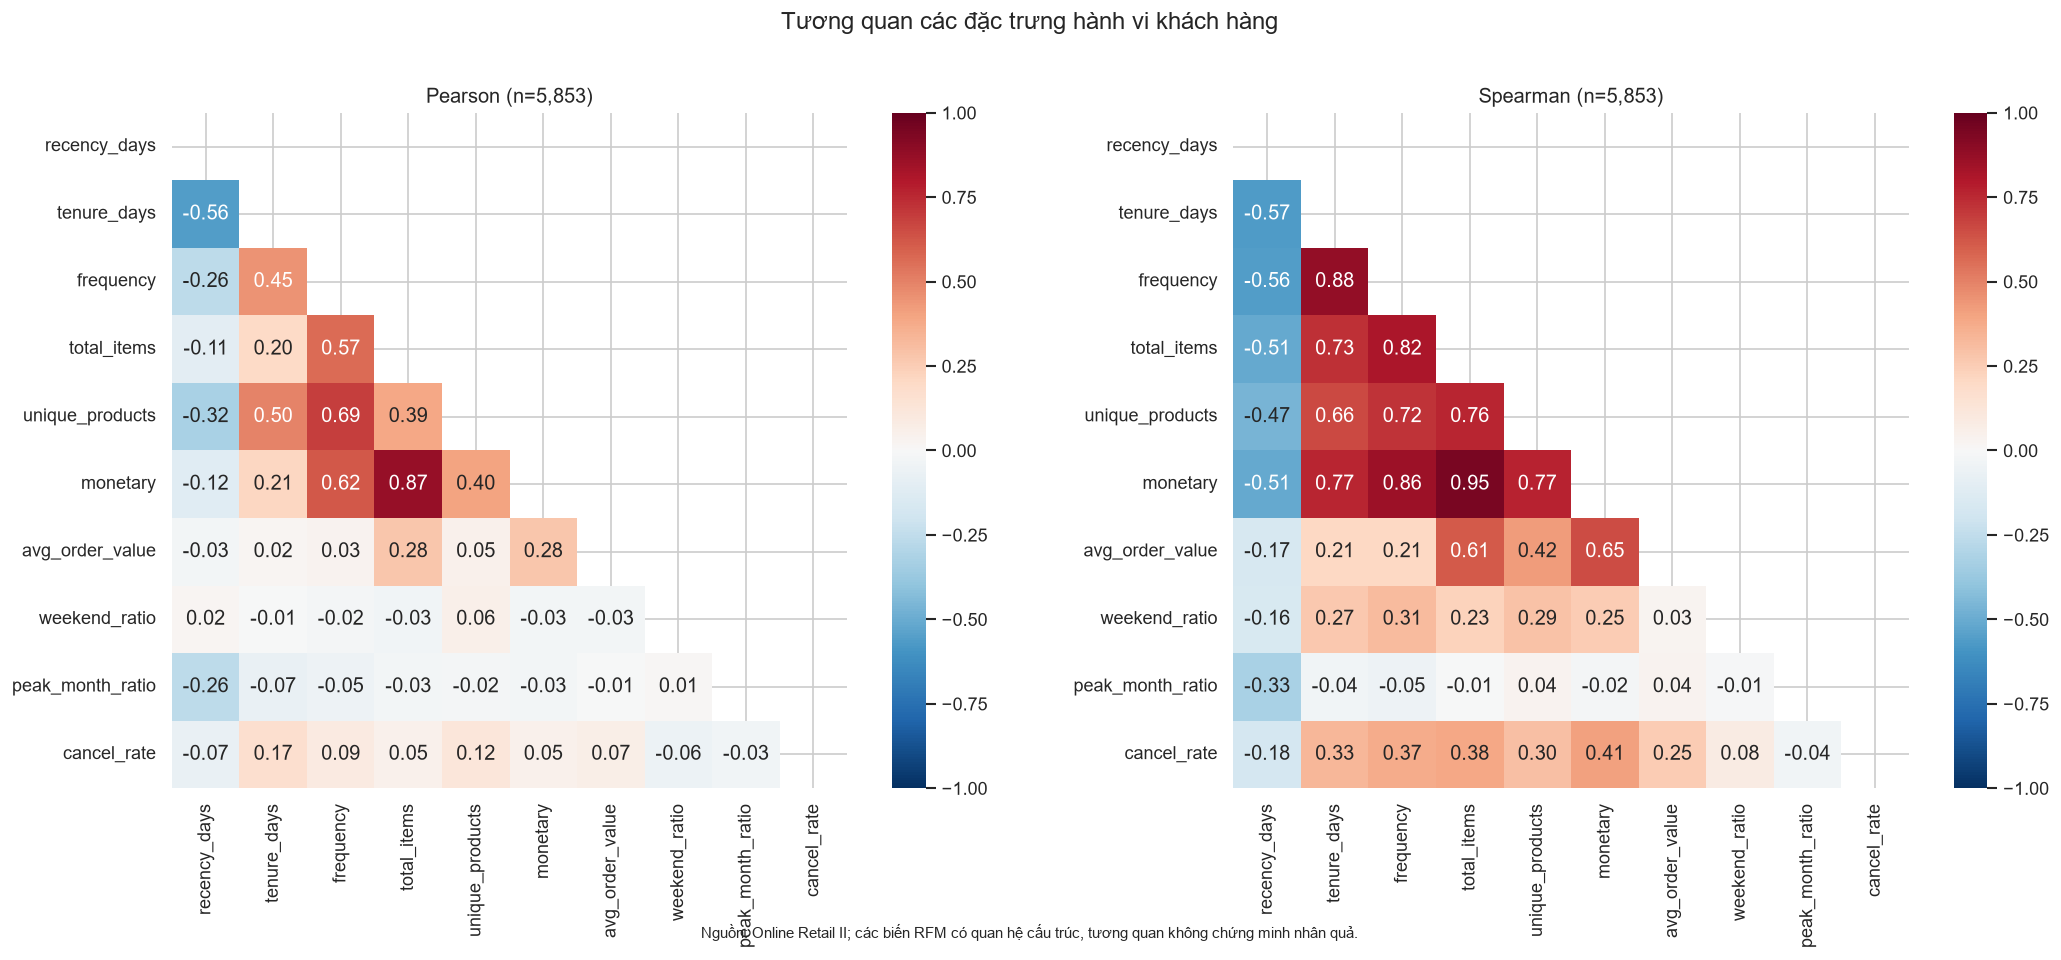

spearman_minus_pearson
monetary        tenure_days                       0.553
total_items     tenure_days                       0.529
frequency       tenure_days                       0.435
total_items     recency_days                     -0.403
monetary        recency_days                     -0.385
avg_order_value unique_products                   0.373
                monetary                          0.373
unique_products total_items                       0.373
monetary        unique_products                   0.369
cancel_rate     monetary                          0.363

In [5]:
# Hai biểu đồ có cùng trục tháng, không dùng hai trục tung
monthly = df_valid.assign(year_month=df_valid['invoice_date'].dt.to_period('M')).groupby('year_month').agg(
    gross_purchase_gbp=('total_amount','sum'),active_customers=('customer_id','nunique'))
months = monthly.index.astype(str).tolist()
x = np.arange(len(months))
# Online Retail II kết thúc 09/12/2011; không so sánh tháng cuối như tháng đầy đủ.
partial = np.array([m == '2011-12' for m in months])
fig, axes = plt.subplots(2,1,figsize=(13,8),sharex=True)
for ax,col,label in zip(axes,['gross_purchase_gbp','active_customers'],['Giá trị mua hợp lệ (£)','Khách có giao dịch mua']):
    bars = ax.bar(x,monthly[col],color=np.where(partial,'#D99B38','#5488C7'))
    for bar,is_partial in zip(bars,partial):
        if is_partial: bar.set_hatch('///')
    ax.set_ylabel(label)
    ax.set_ylim(bottom=0)
axes[-1].set_xticks(x,months,rotation=45,ha='right')
fig.suptitle('Giá trị mua và khách hoạt động theo tháng')
fig.text(.5,.015,'Nguồn: Online Retail II; chỉ dòng mua hợp lệ có ID, chưa trừ hoàn trả. Tháng 12/2011 chỉ đến 09/12 (gạch chéo).',ha='center',fontsize=9)
fig.tight_layout(rect=[0,.05,1,.95])
fig.savefig(ROOT / 'reports/figures/03_monthly_revenue_trend.png',dpi=300,bbox_inches='tight')
plt.show()

# Pearson đo liên hệ tuyến tính; Spearman đo liên hệ đơn điệu theo hạng.
pearson = customer_df[corr_cols].corr(method='pearson')
spearman = customer_df[corr_cols].corr(method='spearman')
fig, axes = plt.subplots(1,2,figsize=(18,8))
for ax, corr, method in zip(axes,[pearson,spearman],['Pearson','Spearman']):
    sns.heatmap(corr,mask=np.triu(np.ones_like(corr,dtype=bool)),annot=True,fmt='.2f',cmap='RdBu_r',center=0,vmin=-1,vmax=1,square=True,ax=ax)
    ax.set_title(f'{method} (n={len(customer_df):,})')
fig.suptitle('Tương quan các đặc trưng hành vi khách hàng')
fig.text(.5,.015,'Nguồn: Online Retail II; các biến RFM có quan hệ cấu trúc, tương quan không chứng minh nhân quả.',ha='center',fontsize=9)
fig.tight_layout(rect=[0,.05,1,.95])
fig.savefig(ROOT / 'reports/figures/04_behavior_correlation_heatmap.png',dpi=300,bbox_inches='tight')
plt.show()
# Các cặp chênh lệch hệ số lớn nhất giúp diễn giải phân phối lệch và ngoại lai.
mask = np.tril(np.ones_like(pearson,dtype=bool),k=-1)
delta = (spearman-pearson).where(mask).stack().rename('spearman_minus_pearson')
display(delta.reindex(delta.abs().sort_values(ascending=False).index).head(10).to_frame().round(3))